# Locate the pages that could contain principal risks

Notebook 01 starts from a **given** page list (`PAGES = [50, 51, 71, ...]`). This notebook finds that list.

The report is cut into **windows of `WINDOW_SIZE` consecutive pages** (with `OVERLAP` pages shared between windows).
Each window is one LLM call. The model sees the pages (as images or as plain text) and gives **every** page a
verdict:

| verdict | meaning |
|---|---|
| `confident` | the page presents specific risks that meet the principal-risk definition |
| `possible` | the page names specific risks, but whether they are principal is unclear |
| `unlikely` | no specific risk to the company on the page |

The model also names the **section** each page belongs to and whether the page **continues** the section from the
page before. Consecutive pages are joined into sections (e.g. p.71-74, one table over four pages), so a whole
section can be sent on even when only some of its pages hold risks.

Pages flagged `confident` (or `confident` + `possible`) go on to the thorough extraction in notebook 01. The step is
tuned for **recall**: a missed page loses its risks for good, while an extra page only costs one more extraction call.

Why verdicts and not a ranking: an earlier attempt (since removed) ranked pages by risk count, and outlook and
financial-note pages outranked the real risk pages. A whole-report call missed p.50-51 entirely, which is why this
notebook uses windows.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import html
import json
import os
import re
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import date
from functools import cache
from typing import Literal

import pandas as pd
import pymupdf
from dotenv import load_dotenv
from IPython.display import HTML, Image, Markdown, display
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field

from annual_report_reader.chat import ReasoningEffort, Usage, azure_chat_model
from annual_report_reader.extraction.config import REPO_ROOT
from annual_report_reader.extraction.pages import PageImage

load_dotenv(REPO_ROOT / ".env")

PDF_PATH = REPO_ROOT / "data/VestasAnnualReport2025.pdf"
PROMPT_DIR = REPO_ROOT / "prompts"
doc = pymupdf.open(PDF_PATH)
DEPLOYMENT = os.environ["AZURE_OPENAI_DEPLOYMENT_LUNA"]

PRINCIPAL_RISK_DEFINITION = (
    (REPO_ROOT / "prompts/principal-risk-definition.md").read_text(encoding="utf-8").removesuffix("\n")
)

# ---- Knobs -------------------------------------------------------------------------------------------------------
PAGES = list(range(1, len(doc) + 1))  # pages to screen (1-indexed PDF pages = case page numbers)
WINDOW_SIZE = 10  # pages the LLM sees per call
OVERLAP = 1  # pages shared by neighbouring windows (context for tables that run across a page break)
INPUT_MODE: Literal["image", "text"] = "image"
DPI = 100  # image mode: render resolution (an A4-landscape page at 100 DPI is 1169x827 px)
IMAGE_DETAIL: Literal["auto", "low", "high"] = "auto"  # image mode: OpenAI image detail setting
REASONING_EFFORT: ReasoningEffort | None = "medium"  # None = the deployment's default
PROMPT = "page-locator"
MAX_WORKERS = 6  # windows sent to the LLM at the same time

# Luna pricing (USD per 1M tokens)
PRICE_IN_PER_M, PRICE_OUT_PER_M = 0.20, 1.20
cost = lambda tin, tout: tin / 1e6 * PRICE_IN_PER_M + tout / 1e6 * PRICE_OUT_PER_M

print(f"{PDF_PATH.name}: {len(doc)} pages | screening {len(PAGES)} | deployment: {DEPLOYMENT}")

VestasAnnualReport2025.pdf: 195 pages | screening 195 | deployment: gpt-5.6-luna-carl-test


## 1. Prompt and output schema

The system prompt is `prompts/<PROMPT>.md`, with `{PRINCIPAL_RISK_DEFINITION}` filled in from
`prompts/principal-risk-definition.md` (the same definition as notebook 01).

The model must return one entry **per page in the window**, so a skipped page can be detected in code.

`section` and `continues_previous` (from v2) are asked for **every** page, also `unlikely` ones: a section such as
p.50-51 (risk management process + main risks) only joins up if the process page has them too.

In [3]:
Verdict = Literal["confident", "possible", "unlikely"]
VERDICT_RANK = {"unlikely": 0, "possible": 1, "confident": 2}


class PageVerdict(BaseModel):
    page: int = Field(description="Page number as given before the page")
    verdict: Verdict
    reason: str = Field(description="One sentence: what on the page supports the verdict")
    candidate_risks: list[str] = Field(
        description="Short names of risks on the page that could be principal; empty if none"
    )
    section: str = Field(description="Heading of the section the page belongs to, as printed")
    continues_previous: bool = Field(
        description="True if the page continues the section, table or list of the page before it"
    )


class WindowVerdicts(BaseModel):
    pages: list[PageVerdict]


SYSTEM = (PROMPT_DIR / f"{PROMPT}.md").read_text(encoding="utf-8")
SYSTEM = SYSTEM.replace("{PRINCIPAL_RISK_DEFINITION}", PRINCIPAL_RISK_DEFINITION)
display(Markdown(f"**{PROMPT}** ({len(SYSTEM):,} chars)\n\n" + SYSTEM))

**page-locator-v2** (4,040 chars)

You screen consecutive pages of a company annual report to find the pages that could contain the company's
principal risks. A later step reads every page you flag in detail and extracts the risks, so a missed page is worse
than a page flagged too many. Flag a page only for what is on it, though: the neighbouring pages are context, not
evidence.

Each page is preceded by its page number (e.g. "Page 51"). Use those numbers, not page numbers printed on the page.

## Definition of a principal risk

A principal risk is an uncertain event or condition that the reporting company
itself presents as having the potential to materially affect its strategy,
financial performance, operations, reputation, or viability, and as significant
enough to warrant board- or executive-level attention.

A principal risk has these characteristics:
- **It is a risk to the company.** It describes how external or internal
  factors could affect the company (outside-in), not how the company affects
  people or the environment (inside-out).
- **It has downside potential.** Opportunities, even uncertain ones, are not
  risks.
- **It is material.** The company presents it as significant, for example by
  listing it among its main or key risks, describing it as material, or
  linking it to its strategy, financial outlook, or viability. Risks the
  company assesses as immaterial are not principal risks.
- **It is specific to the company.** Generic statements that could apply to
  any company, or catch-all references to unknown risks, do not qualify unless
  the company presents them as principal.

Whether a risk is principal is determined by how the company presents it in
the report, not by an independent judgment of how serious it is.

For every page you are given, return exactly one entry with:

- page: the page number given before the page.
- verdict:
  - confident: the page itself presents one or more specific risks that meet the definition. Examples: a list or grid
    of main, key or principal risks; a table of material risks (including tables that mark items as risks, impacts
    or opportunities, if at least one item is a risk to the company); a section dedicated to one specific risk
    (e.g. cyber security or climate-related transition risk) with its description or mitigation.
  - possible: the page names specific risks to the company, but it is unclear whether they meet the definition.
    Examples: risks the company may present as minor or immaterial; risks named in an outlook or strategy section;
    financial risk notes (currency, interest rate, credit, liquidity); risk text that continues from the previous
    page.
  - unlikely: the page names no specific risk to the company. Examples: table of contents; descriptions of how risk
    is managed that do not name the risks; impacts the company has on people or the environment only;
    opportunities only; passing mentions of the word "risk"; financial statements without risk discussion.
- reason: one sentence on what on the page supports the verdict (name the heading or table if there is one).
- candidate_risks: short names of the risks on the page that could be principal risks. Empty for unlikely pages.
- section: the section the page belongs to, as printed: the heading at the top of the page, or the running section
  name in the page header if the page has no heading of its own. Prefer the most specific heading that covers the
  whole page (e.g. "Material impacts, risks and opportunities", not "Sustainability statement").
- continues_previous: true if the page continues the same section, table or list as the page given just before it
  (the same heading carries on, or a table or list runs over the page break). False if a new section starts at the
  top of the page. For the first page you are given, you cannot see the page before it: return false.

Read every page in full, including tables, diagrams, side boxes and legends. Give every page a section and a continues_previous
value, whatever its verdict. Return the entries in page order.


## 2. Helpers

`windows` cuts `PAGES` into chunks. `locate_window` sends one chunk through a LangChain chat model with strict
structured output (`WindowVerdicts`). Every call goes to the API.

In [4]:
_render_lock = threading.Lock()  # PyMuPDF is not thread-safe; windows run in parallel


def windows(pages: list[int], size: int, overlap: int) -> list[list[int]]:
    # Consecutive chunks of `size` pages; neighbours share `overlap` pages. The last chunk may be shorter.
    assert size >= 1 and 0 <= overlap < size, "need size >= 1 and 0 <= overlap < size"
    out = []
    for start in range(0, len(pages), size - overlap):
        out.append(pages[start : start + size])
        if start + size >= len(pages):
            break
    return out


def page_png(page_number: int, dpi: int) -> bytes:
    with _render_lock:
        return doc[page_number - 1].get_pixmap(dpi=dpi).tobytes("png")


def page_text(page_number: int) -> str:
    with _render_lock:
        return doc[page_number - 1].get_text("text").strip()


def window_content(chunk: list[int], mode: str, dpi: int, detail: str) -> list[dict]:
    # User-message parts: "Page n" before each page, then the page as an image or as plain text.
    parts: list[dict] = []
    for p in chunk:
        if mode == "image":
            url = PageImage(p, page_png(p, dpi)).data_url
            parts += [
                {"type": "text", "text": f"Page {p}"},
                {"type": "image_url", "image_url": {"url": url, "detail": detail}},
            ]
        else:
            parts.append({"type": "text", "text": f"Page {p}\n\n{page_text(p)}"})
    return parts


@cache
def locator(effort: ReasoningEffort | None):
    # Chat model + strict structured output; {"raw", "parsed", "parsing_error"} per call. One per effort setting.
    model = azure_chat_model(DEPLOYMENT, effort)
    return model.with_structured_output(WindowVerdicts, method="json_schema", strict=True, include_raw=True)


def locate_window(
    chunk: list[int],
    mode: str = INPUT_MODE,
    dpi: int = DPI,
    detail: str = IMAGE_DETAIL,
    effort: ReasoningEffort | None = REASONING_EFFORT,
) -> dict:
    # One window -> WindowVerdicts via structured output.
    content = window_content(chunk, mode, dpi, detail)
    out = locator(effort).invoke([SystemMessage(SYSTEM), HumanMessage(content=content)])
    if out["parsed"] is None:
        raise ValueError(f"window {chunk[0]}-{chunk[-1]}: no parsed output ({out['parsing_error']!r})")
    usage = Usage.of(out["raw"])
    rec = {
        "window": chunk,
        "mode": mode,
        "dpi": dpi if mode == "image" else None,
        "detail": detail if mode == "image" else None,
        "model": DEPLOYMENT,
        "prompt": PROMPT,
        "reasoning_effort": effort,
        "response": out["parsed"].model_dump(mode="json"),
        "tokens_in": usage.input_tokens,
        "tokens_out": usage.output_tokens,
        "tokens_reasoning": usage.reasoning_tokens,
    }
    return {**rec, "parsed": out["parsed"]}


def show_table(df: pd.DataFrame) -> None:
    table = df.map(lambda v: html.escape(", ".join(v) if isinstance(v, list) else str(v))).to_html(
        escape=False, index=False
    )
    display(HTML(f"<div style='font-size:12px;text-align:left'>{table}</div>"))

## 3. Run all windows

`run_locator` returns one row per screened page. Where windows overlap, the **highest** verdict wins (recall first);
`seen_in` lists every window's verdict for that page, so disagreements stay visible.

Code checks: page numbers outside the window are dropped, and a page the model skipped gets `possible` with the reason
"(not returned by the model)", so it is still checked later instead of silently lost.

**Section continuity.** A page continues the page before it if the model says so **or** both pages have the same
`section` heading (ignoring case and punctuation). `continuity_from` says which: `model`, `heading match` or both.
The model's `continues_previous` is only trusted from a window that also showed the page before: the first page of a
window has no previous page in view, and with `OVERLAP >= 1` the previous window covers that page pair. The heading
rule catches the model's inconsistencies (first run: p.74 had the same heading as p.73 but `continues_previous =
false`, which split the p.71-74 table) and covers window boundaries when `OVERLAP = 0`. `group_sections` then joins each run of continuing pages into one section, whose
verdict is the highest of its pages.

In [5]:
def _norm_heading(s: str) -> str:
    return re.sub(r"\W+", " ", s or "").strip().lower()


def run_locator(
    pages: list[int] = PAGES,
    size: int = WINDOW_SIZE,
    overlap: int = OVERLAP,
    mode: str = INPUT_MODE,
    dpi: int = DPI,
    detail: str = IMAGE_DETAIL,
    effort: ReasoningEffort | None = REASONING_EFFORT,
    workers: int = MAX_WORKERS,
    verbose: bool = True,
) -> tuple[pd.DataFrame, dict]:
    chunks = windows(pages, size, overlap)
    done, errors = {}, {}
    with ThreadPoolExecutor(max_workers=workers) as pool:
        futures = {pool.submit(locate_window, c, mode, dpi, detail, effort): i for i, c in enumerate(chunks)}
        for fut in as_completed(futures):
            i = futures[fut]
            c = chunks[i]
            try:
                done[i] = r = fut.result()
                if verbose:
                    flagged = [v.page for v in r["parsed"].pages if v.verdict != "unlikely"]
                    print(
                        f"p.{c[0]:>3}-{c[-1]:<3} | flagged {flagged} "
                        f"| in {r['tokens_in']:,} / out {r['tokens_out']:,} | ${cost(r['tokens_in'], r['tokens_out']):.4f}"
                    )
            except Exception as e:  # noqa: BLE001 - one failing window should not lose the others
                errors[i] = e
                print(f"p.{c[0]:>3}-{c[-1]:<3} FAILED: {e!r}")

    best: dict[int, dict] = {}
    seen: dict[int, list[str]] = {}
    cont: dict[int, list[bool]] = {}  # continues_previous, only from windows that also showed page - 1
    for i in sorted(done):
        chunk, returned = chunks[i], set()
        for v in done[i]["parsed"].pages:
            if v.page not in chunk or v.page in returned:
                print(f"window {chunk[0]}-{chunk[-1]}: dropped entry for p.{v.page} (outside window or duplicate)")
                continue
            returned.add(v.page)
            seen.setdefault(v.page, []).append(f"{chunk[0]}-{chunk[-1]}:{v.verdict}")
            if v.page - 1 in chunk:
                cont.setdefault(v.page, []).append(v.continues_previous)
            if v.page not in best or VERDICT_RANK[v.verdict] > VERDICT_RANK[best[v.page]["verdict"]]:
                best[v.page] = v.model_dump()
        for p in set(chunk) - returned:
            print(f"window {chunk[0]}-{chunk[-1]}: p.{p} not returned -> possible")
            seen.setdefault(p, []).append(f"{chunk[0]}-{chunk[-1]}:missing")
            if p not in best or VERDICT_RANK[best[p]["verdict"]] < VERDICT_RANK["possible"]:
                best[p] = {
                    "page": p,
                    "verdict": "possible",
                    "reason": "(not returned by the model)",
                    "candidate_risks": [],
                    "section": best.get(p, {}).get("section", ""),
                    "continues_previous": False,
                }
    failed_pages = sorted({p for i in errors for p in chunks[i]} - set(best))

    rows, prev = [], None
    for p in pages:
        if p not in best:
            prev = None
            continue
        b = best[p]
        model_says = any(cont.get(p, []))  # only from windows that showed p - 1 and p together
        same_heading = (
            prev is not None
            and prev["page"] == p - 1
            and bool(_norm_heading(b["section"]))
            and _norm_heading(b["section"]) == _norm_heading(prev["section"])
        )
        c = model_says or same_heading
        src = (
            "model + heading"
            if model_says and same_heading
            else "model"
            if model_says
            else "heading match"
            if same_heading
            else "-"
        )
        rows.append({**b, "continues_previous": c, "continuity_from": src, "seen_in": seen.get(p, [])})
        prev = b

    df = pd.DataFrame(
        rows,
        columns=[
            "page",
            "verdict",
            "section",
            "continues_previous",
            "continuity_from",
            "reason",
            "candidate_risks",
            "seen_in",
        ],
    )
    tin = sum(r["tokens_in"] for r in done.values())
    tout = sum(r["tokens_out"] for r in done.values())
    usage = {
        "windows": len(chunks),
        "failed_windows": len(errors),
        "failed_pages": failed_pages,
        "tokens_in": tin,
        "tokens_out": tout,
        "cost_usd": round(cost(tin, tout), 4),
    }
    return df, usage


def group_sections(df: pd.DataFrame) -> pd.DataFrame:
    # Joins consecutive pages linked by continues_previous into sections; one row per section.
    groups: list[list] = []
    for r in df.itertuples():
        if groups and r.continues_previous and r.page == groups[-1][-1].page + 1:
            groups[-1].append(r)
        else:
            groups.append([r])
    rows = []
    for g in groups:
        top = max(g, key=lambda r: VERDICT_RANK[r.verdict])
        rows.append(
            {
                "pages": f"{g[0].page}-{g[-1].page}" if len(g) > 1 else str(g[0].page),
                "first": g[0].page,
                "last": g[-1].page,
                "section": g[0].section,
                "verdict": top.verdict,
                "page_verdicts": " ".join(f"{r.page}:{r.verdict}" for r in g),
                "candidate_risks": list(dict.fromkeys(c for r in g for c in r.candidate_risks)),
            }
        )
    return pd.DataFrame(
        rows, columns=["pages", "first", "last", "section", "verdict", "page_verdicts", "candidate_risks"]
    )


def section_pages(secs: pd.DataFrame, keep: set[str]) -> set[int]:
    # Every page of the sections whose verdict is in `keep`.
    return {p for r in secs[secs.verdict.isin(keep)].itertuples() for p in range(r.first, r.last + 1)}


located, usage = run_locator()
sections = group_sections(located)
counts = located.verdict.value_counts().reindex(["confident", "possible", "unlikely"], fill_value=0)
print(
    f"\n{len(located)} pages screened in {usage['windows']} windows | "
    + " | ".join(f"{k} {v}" for k, v in counts.items())
    + f" | {len(sections)} sections | in {usage['tokens_in']:,} / out {usage['tokens_out']:,} tokens | ${usage['cost_usd']:.4f}"
    + (f" | FAILED pages: {usage['failed_pages']}" if usage["failed_pages"] else "")
)

p. 46-55  | flagged [50, 51] | in 12,685 / out 927 | $0.0036
p. 19-28  | flagged [22, 25, 26, 27] | in 12,685 / out 889 | $0.0036
p. 28-37  | flagged [29, 30, 31, 32, 33, 34, 37] | in 12,685 / out 1,176 | $0.0039
p. 10-19  | flagged [10, 11, 16, 17] | in 12,685 / out 1,208 | $0.0040
p.  1-10  | flagged [3, 4, 10] | in 12,685 / out 1,126 | $0.0039
p. 37-46  | flagged [37, 39, 40] | in 12,685 / out 1,379 | $0.0042
p. 55-64  | flagged [] | in 12,685 / out 878 | $0.0036
p. 91-100 | flagged [] | in 12,685 / out 1,085 | $0.0038
p. 64-73  | flagged [64, 65, 66, 67, 69, 71, 72, 73] | in 12,685 / out 2,077 | $0.0050
p.100-109 | flagged [101, 102, 106, 108, 109] | in 12,685 / out 1,427 | $0.0042
p. 82-91  | flagged [85, 86, 87] | in 12,685 / out 2,158 | $0.0051
p. 73-82  | flagged [73, 74, 77, 78, 81, 82] | in 12,685 / out 2,258 | $0.0052
p.109-118 | flagged [109, 110, 112, 114, 116, 117, 118] | in 12,685 / out 1,674 | $0.0045
p.136-145 | flagged [142] | in 12,685 / out 840 | $0.0035
p.118-127 |

In [12]:
# Flagged pages (confident first, then possible)
rank = located.verdict.map(VERDICT_RANK)
flagged = (
    located[rank > 0].assign(_rank=rank).sort_values(["_rank", "page"], ascending=[False, True]).drop(columns="_rank")
)
show_table(flagged)

page,verdict,section,continues_previous,continuity_from,reason,candidate_risks,seen_in
31,confident,Offshore,False,-,"The Offshore performance page explicitly describes rising supply-chain and financing costs, political and geopolitical factors, failed auctions, and market and policy recalibration affecting offshore wind execution.","Supply-chain disruption, Financing-cost increases, Political and geopolitical uncertainty, Failed or delayed auctions, Unfavourable tender and policy design",28-37:confident
51,confident,Main risks,False,-,"The Main risks table presents specific risks—Geopolitics and regulatory framework, Project execution, and Cyber attacks—with descriptions of their potential impacts and management.","Geopolitics and regulatory framework, Project execution, Cyber attacks",46-55:confident
67,confident,Energy transition highlights,False,-,"The Energy transition highlights page has dedicated discussions of geopolitical risks and cyber security, including cyber-risk management and mitigation.","Geopolitical risks, Cyber security, Anti-corruption and bribery",64-73:confident
69,confident,Result of the double materiality assessment,False,-,"The double materiality assessment explicitly identifies material impacts, risks and opportunities and presents financially material topics including climate change, working conditions, cyber security and corruption.","Climate change mitigation and adaptation, Resource outflows, Working conditions, Cyber security, Corruption and bribery",64-73:confident
71,confident,"Material impacts, risks, and opportunities",False,-,"The Material impacts, risks, and opportunities table identifies financially material carbon taxes and tariffs as a risk and also notes other climate-related financial risks or opportunities.","Carbon taxes and tariffs, Climate change-related financial risks",64-73:confident
73,confident,"Material impacts, risks, and opportunities",True,model + heading,"The materiality tables identify financially material risks from workplace injuries, contractor and subcontractor incidents, and fines related to forced or child labour.","Cost implications of own-workforce injuries, Cost implications of contractor and subcontractor injuries, Fines related to forced or child labour","64-73:confident, 73-82:confident"
74,confident,Affected communities,False,-,"The G1 Business Conduct financial risks or opportunities table specifically identifies insufficient market conditions, cyber security risks, and corruption and bribery.","Insufficient market conditions, Cyber security, Corruption and bribery",73-82:confident
85,confident,"Impacts, risks, and opportunities",False,-,"The “Impacts, risks, and opportunities” table explicitly identifies carbon taxes and tariffs as a financial transition risk that could increase costs and affect Vestas’s business outlook.",Carbon taxes and tariffs,82-91:confident
101,confident,S1 – Own workforce — Health and safety,False,-,"The “Health and safety” page explicitly presents “Impacts, risks, and opportunities,” including health and safety incidents in the own workforce and related risk controls.","Own-workforce health and safety incidents, Workplace injuries",100-109:confident
108,confident,S2 — Workers in the value chain,False,-,"The “Workers in the value chain” page contains an explicit “Impacts, risks, and opportunities” table identifying contractor and supply-chain health and safety, child or forced labour, cost, and fines risks.","Contractor health and safety incidents, Supply-chain worker health and safety incidents, Child or forced labour, Cost implications of contractor injuries, Fines related to forced or child labour",100-109:confident


### 3b. Sections

One row per section: the pages it spans, its heading (from its first page), its verdict (the highest of its pages) and
every page's verdict. Only sections with at least one flagged page are shown. A section that runs too long (e.g. a whole
chapter) means `continues_previous` is too generous; one that breaks a known table in two means it is too strict.

In [7]:
flagged_sections = sections[sections.verdict != "unlikely"]
n_pages = int((flagged_sections["last"] - flagged_sections["first"] + 1).sum())
print(
    f"{len(sections)} sections | flagged: {len(flagged_sections)} sections covering {n_pages} pages "
    f"({len(flagged)} flagged pages on their own)"
)
show_table(flagged_sections.drop(columns=["first", "last"]))

129 sections | flagged: 52 sections covering 103 pages (74 flagged pages on their own)


pages,section,verdict,page_verdicts,candidate_risks
3-4,Letter from the Chair & CEO,possible,3:possible 4:possible,"Geopolitical tensions, Supply-chain disruption, Trade disruption and protectionism, Power-price increases, Climate-policy and regulatory uncertainty, Market challenges, Operational and cost pressures, Execution risk, Geopolitical uncertainty"
10,Our people,possible,10:possible,"Operational risks, Workforce dependency risks, Workplace safety risk"
11,Outlook,possible,11:possible,"Geopolitical risk, Tariff risk, Regulatory disruption, Supply-chain disruption, Extreme weather, Foreign exchange risk, Grid-connection constraints"
16,Market outlook and wind energy value drivers,possible,16:possible,"Permitting bottlenecks, Auction-design constraints, Regulatory change, Policy uncertainty"
17,Energy affordability,possible,17:possible,"Inflation, Reduced subsidies, Electricity taxation, Rising electricity costs"
22,Capital structure strategy,possible,22:possible,"Economic and market fluctuations, Liquidity and financing, Capital structure and leverage"
25-26,Group financial performance,possible,25:possible 26:possible,"Warranty costs, Foreign exchange rate movements, Revenue and demand pressure, Operating cost pressure, Working capital requirements, Cash flow and investment pressure, Financing and leverage, Interest-bearing debt"
27,Power solutions,possible,27:possible,"Declining order intake, Offshore demand pressure, Geographic and project-mix risk"
29,Onshore,possible,29:possible,"Energy-price volatility, Permitting constraints, Policy uncertainty, Weak auction demand"
30,Onshore strategy,possible,30:possible,"Permitting constraints, Grid infrastructure constraints, Energy-storage constraints, Policy uncertainty"


## 4. Check against the golden pages

There is no golden "page list" file, so two references are used:

- **golden**: the pages with at least one risk in `eval/golden/risk_extraction.yaml`. The file also lists pages
  with no risks (p.50, p.72); they show whether the model flags the neighbours of risk pages.
- **case**: the pages the case brief points to (MUST 50-51 and 71-74, MAY 85-92 and 118).

Only these pages were labelled, so a flagged page outside them is **not** necessarily wrong: look at those
pages in section 5. "Precision" below is therefore a lower bound and is not reported as a score.

In [8]:
from annual_report_reader.evaluation.golden import load_golden

GOLDEN_FILE = REPO_ROOT / "eval/golden/risk_extraction.yaml"
golden = load_golden(GOLDEN_FILE)  # labelled page -> its risks ([] = labelled, no risks)
GOLDEN_PAGES = {p for p, risks in golden.items() if risks}
LABELLED_PAGES = set(golden)
CASE_RANGES = {
    "Risk management (MUST)": (50, 51),
    "Material impacts, risks and opportunities (MUST)": (71, 74),
    "Climate change (MAY)": (85, 92),
    "Cyber security (MAY)": (118, 118),
}
CASE_PAGES = {p for a, b in CASE_RANGES.values() for p in range(a, b + 1)}
print(
    f"golden pages (with risks): {sorted(GOLDEN_PAGES)} | labelled with no risks: {sorted(LABELLED_PAGES - GOLDEN_PAGES)}"
)

CUTOFFS = {"confident": {"confident"}, "confident+possible": {"confident", "possible"}}


def score(df: pd.DataFrame, secs: pd.DataFrame, n_screened: int | None = None) -> dict:
    # Recall of the golden and case pages per cut-off, flagged pages alone vs whole flagged sections.
    n_screened = n_screened or len(df)
    out = {}
    for name, keep in CUTOFFS.items():
        for unit, sent in {"pages": set(df.page[df.verdict.isin(keep)]), "sections": section_pages(secs, keep)}.items():
            out[f"{name} ({unit})"] = {
                "pages sent on": len(sent),
                "share of report": round(len(sent) / n_screened, 3),
                "golden recall": round(len(GOLDEN_PAGES & sent) / len(GOLDEN_PAGES), 2),
                "golden missed": sorted(GOLDEN_PAGES - sent),
                "case recall": round(len(CASE_PAGES & sent) / len(CASE_PAGES), 2),
                "case missed": sorted(CASE_PAGES - sent),
                "no-risk pages flagged": sorted((LABELLED_PAGES - GOLDEN_PAGES) & sent),
                "flagged, not labelled": len(sent - LABELLED_PAGES - CASE_PAGES),
            }
    return out


def range_check(secs: pd.DataFrame) -> pd.DataFrame:
    # For each page range the case brief names: which found sections overlap it, and is it found as exactly one section?
    rows = []
    for name, (a, b) in CASE_RANGES.items():
        hit = secs[(secs["first"] <= b) & (secs["last"] >= a)]
        rows.append(
            {
                "case range": f"{name}: p.{a}-{b}" if a != b else f"{name}: p.{a}",
                "found as": " | ".join(f"{r.pages} {r.verdict} ({r.section})" for r in hit.itertuples()),
                "exact": len(hit) == 1 and hit.iloc[0]["first"] == a and hit.iloc[0]["last"] == b,
            }
        )
    return pd.DataFrame(rows)


scores = score(located, sections)
display(pd.DataFrame(scores))
show_table(range_check(sections))

# Every golden / case page with its verdict and section
ref = located[located.page.isin(GOLDEN_PAGES | CASE_PAGES)].copy()
ref.insert(1, "golden risks", ref.page.map({p: len(r) for p, r in golden.items()}).fillna(0).astype(int))
show_table(ref.drop(columns=["candidate_risks"]))

golden pages (with risks): [51, 71, 73, 74, 85, 118] | labelled with no risks: [50, 72]


,confident (pages),confident (sections),confident+possible (pages),confident+possible (sections)
pages sent on,20,34,74,103
share of report,0.103,0.174,0.379,0.528
golden recall,1.0,1.0,1.0,1.0
golden missed,[],[],[],[]
case recall,0.4,0.93,0.67,1.0
case missed,"[50, 72, 86, 87, 88, 89, 90, 91, 92]",[50],"[88, 89, 90, 91, 92]",[]
no-risk pages flagged,[],[72],"[50, 72]","[50, 72]"
"flagged, not labelled",14,20,64,88


case range,found as,exact
Risk management (MUST): p.50-51,50 possible (Risk management) | 51 confident (Main risks),False
"Material impacts, risks and opportunities (MUST): p.71-74","71-73 confident (Material impacts, risks, and opportunities) | 74 confident (Affected communities)",False
Climate change (MAY): p.85-92,"85-92 confident (Impacts, risks, and opportunities)",True
Cyber security (MAY): p.118,118-119 confident (Cyber security),False


page,golden risks,verdict,section,continues_previous,continuity_from,reason,seen_in
50,0,possible,Risk management,False,-,"The Risk management page identifies operational, commercial, macroeconomic, regulatory, and material sustainability risks as significant enterprise risks but does not describe them individually.",46-55:possible
51,4,confident,Main risks,False,-,"The Main risks table presents specific risks—Geopolitics and regulatory framework, Project execution, and Cyber attacks—with descriptions of their potential impacts and management.",46-55:confident
71,1,confident,"Material impacts, risks, and opportunities",False,-,"The Material impacts, risks, and opportunities table identifies financially material carbon taxes and tariffs as a risk and also notes other climate-related financial risks or opportunities.",64-73:confident
72,0,possible,"Material impacts, risks, and opportunities",True,model + heading,"The page names biodiversity, resource inflow and waste-related risks but explicitly states that they were scored as immaterial.",64-73:possible
73,3,confident,"Material impacts, risks, and opportunities",True,model + heading,"The materiality tables identify financially material risks from workplace injuries, contractor and subcontractor incidents, and fines related to forced or child labour.","64-73:confident, 73-82:confident"
74,3,confident,Affected communities,False,-,"The G1 Business Conduct financial risks or opportunities table specifically identifies insufficient market conditions, cyber security risks, and corruption and bribery.",73-82:confident
85,1,confident,"Impacts, risks, and opportunities",False,-,"The “Impacts, risks, and opportunities” table explicitly identifies carbon taxes and tariffs as a financial transition risk that could increase costs and affect Vestas’s business outlook.",82-91:confident
86,0,possible,Climate Change,True,model,"The “Resilience analysis” section identifies physical risks such as water stress and extreme rainfall and transition risks that could disrupt operations, while noting that some impacts are not financially material.",82-91:possible
87,0,possible,Climate Change,True,model + heading,"The page states that upcoming carbon taxes and tariffs will increase costs for low-emission steel and could affect the company’s supply-chain decarbonisation efforts, although materiality is not clearly stated.",82-91:possible
88,0,unlikely,Climate Change,True,model + heading,"The page reports Scope 3 emissions targets, energy consumption, and methodology changes without presenting a specific risk to Vestas.",82-91:unlikely


## 5. Inspect a page: the image next to the verdict

Use it on misses (golden pages marked `unlikely`) and on flagged pages outside the labelled set, to decide whether
the prompt or the golden set is wrong.

**Page 51: `confident`** (46-55:confident)  
section: *Main risks* (starts a section, from -)  
The Main risks table presents specific risks—Geopolitics and regulatory framework, Project execution, and Cyber attacks—with descriptions of their potential impacts and management.  
candidates: Geopolitics and regulatory framework, Project execution, Cyber attacks

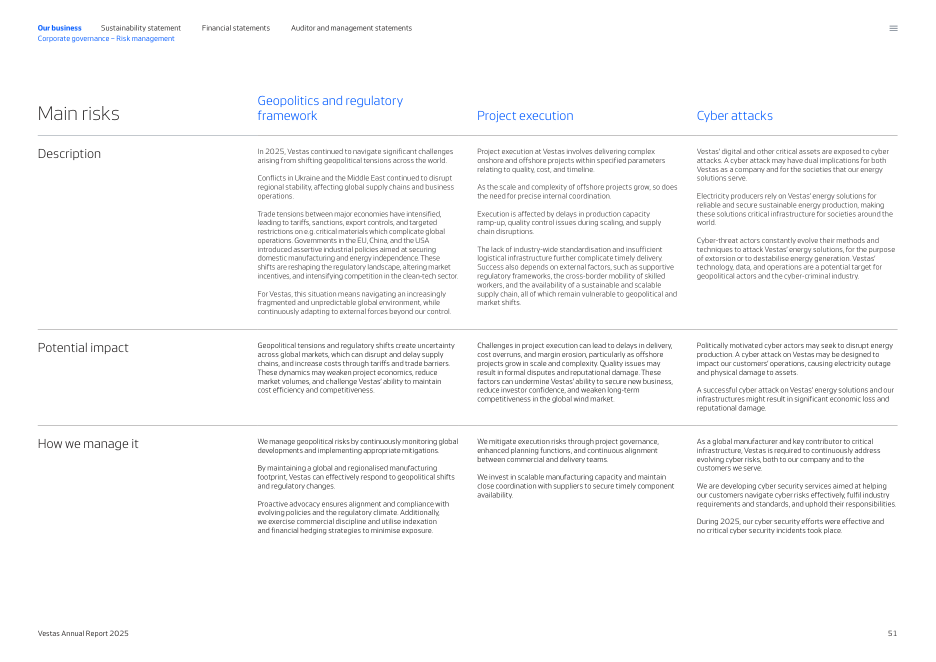

In [9]:
def show_verdict(page: int, dpi: int = 80) -> None:
    row = located[located.page == page]
    if row.empty:
        print(f"p.{page} was not screened")
    else:
        r = row.iloc[0]
        cont = f"continues p.{page - 1}" if r.continues_previous else "starts a section"
        display(
            Markdown(
                f"**Page {page}: `{r.verdict}`** ({', '.join(r.seen_in)})  \n"
                f"section: *{r.section}* ({cont}, from {r.continuity_from})  \n{r.reason}  \n"
                f"candidates: {', '.join(r.candidate_risks) or '-'}"
            )
        )
    display(Image(page_png(page, dpi)))


INSPECT_PAGE = 51
show_verdict(INSPECT_PAGE)

# Flagged pages outside the labelled set:
# for p in sorted(set(flagged.page) - LABELLED_PAGES - CASE_PAGES): show_verdict(p)

## 6. Sweep: how many pages per call?

Runs the whole report once per setting and compares recall, the pages sent on, and the cost. Each new setting costs
about one full-report pass (a few cents with Luna, text mode cheaper than images).
Off by default: set `RUN_SWEEP = True`.

Things worth comparing: `WINDOW_SIZE` 1 (no context, many calls) vs 5 / 10 / 20 (more context, more pages to keep
track of per call); `image` vs `text`; `IMAGE_DETAIL="low"` (much cheaper, but small body text may be unreadable).

In [10]:
RUN_SWEEP = False
SWEEP = [  # (window size, overlap, mode)
    (1, 0, "image"),
    (5, 1, "image"),
    (10, 1, "image"),
    (20, 1, "image"),
    (10, 1, "text"),
]

sweep_rows = []
if RUN_SWEEP:
    for size, overlap, mode in SWEEP:
        df_s, usage_s = run_locator(size=size, overlap=overlap, mode=mode, verbose=False)
        secs_s = group_sections(df_s)
        s = score(df_s, secs_s)
        sweep_rows.append(
            {
                "window": size,
                "overlap": overlap,
                "mode": mode,
                "cost_usd": usage_s["cost_usd"],
                "tokens_in": usage_s["tokens_in"],
                "failed_pages": usage_s["failed_pages"],
                "sections": len(secs_s),
                "case ranges exact": int(range_check(secs_s)["exact"].sum()),
                **{
                    f"{cut}: {k}": v
                    for cut, d in s.items()
                    for k, v in d.items()
                    if k in ("pages sent on", "golden recall", "golden missed", "case recall")
                },
            }
        )
    display(pd.DataFrame(sweep_rows))

## 7. Save the run to `eval/runs/`

In [11]:
RUNS_DIR = REPO_ROOT / "eval/runs"
run_name = f"{date.today()}-locate-{PROMPT}-{INPUT_MODE}-w{WINDOW_SIZE}o{OVERLAP}-{REASONING_EFFORT or 'default'}"
run = {
    "config": {
        "model": DEPLOYMENT,
        "prompt": PROMPT,
        "reasoning_effort": REASONING_EFFORT,
        "input_mode": INPUT_MODE,
        "dpi": DPI if INPUT_MODE == "image" else None,
        "image_detail": IMAGE_DETAIL if INPUT_MODE == "image" else None,
        "window_size": WINDOW_SIZE,
        "overlap": OVERLAP,
        "pages": [PAGES[0], PAGES[-1]] if PAGES == list(range(PAGES[0], PAGES[-1] + 1)) else PAGES,
        "golden": str(GOLDEN_FILE.relative_to(REPO_ROOT)),
        "system_prompt": SYSTEM,
    },
    "usage": usage,
    "scores": scores,
    "case_ranges": range_check(sections).to_dict("records"),
    "sweep": sweep_rows,
    "verdicts": located.to_dict("records"),
    "sections": sections.to_dict("records"),
}
RUNS_DIR.mkdir(parents=True, exist_ok=True)
out = RUNS_DIR / f"{run_name}.json"
out.write_text(json.dumps(run, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"Saved {out}")

Saved /home/carl/git/personal/tech-challenge/eval/runs/2026-11-12-locate-page-locator-v2-image-w10o1-medium.json


## 8. Observations

This does seem to work fairly well. We can cut down the amount of calls by a large piece.